<a href="https://colab.research.google.com/github/haricharansai/Deep-Learning-With-Accelerated-Computing-2.2/blob/main/VisionPort_Dataset_Audit_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VisionPort – Dataset Audit, Visualisation & Defect Detection

This notebook automatically downloads **COCO128** through Ultralytics, creates a separate test copy with intentionally introduced defects, and audits that copy.

No Google Drive, manual dataset upload, or API key is required. Run all cells from top to bottom.

The audit covers class distribution, image quality, corrupted images, exact duplicates, missing/empty labels, invalid YOLO bounding boxes, visualisation, and CSV reports.

**Dataset note:** COCO128 is a small 128-image COCO sample, not a dedicated traffic-only dataset. It includes road-related categories such as person, bicycle, car, motorcycle, bus and truck. Defects are injected only into a separate copy; the original download is unchanged.


In [ ]:
# 1. Install dependencies
!pip -q install -U ultralytics opencv-python-headless pandas matplotlib seaborn tqdm


In [ ]:

# 2. Automatically download COCO8
from pathlib import Path
from ultralytics.data.utils import check_det_dataset

dataset = check_det_dataset("coco128.yaml")

DATASET_ROOT = Path(dataset["path"])
IMAGE_DIR = DATASET_ROOT / "images" / "train2017"
LABEL_DIR = DATASET_ROOT / "labels" / "train2017"

if not IMAGE_DIR.exists() or not LABEL_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folders not found. Images: {IMAGE_DIR}; Labels: {LABEL_DIR}"
    )

print("COCO8 downloaded.")
print("Dataset:", DATASET_ROOT)
print("Images:", IMAGE_DIR)
print("Labels:", LABEL_DIR)
print("Classes:", len(dataset["names"]))


COCO8 downloaded.
Dataset: /content/datasets/coco128
Images: /content/datasets/coco128/images/train2017
Labels: /content/datasets/coco128/labels/train2017
Classes: 80


In [ ]:
# 3. Imports and indexing original dataset
import os, shutil, hashlib, cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from pathlib import Path
from tqdm.auto import tqdm
from IPython.display import display

CLASS_NAMES = dataset["names"]
NUM_CLASSES = len(CLASS_NAMES)
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

original_image_paths = sorted(
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)
original_records = []
for image_path in original_image_paths:
    relative = image_path.relative_to(IMAGE_DIR).with_suffix(".txt")
    original_records.append({
        "image": image_path,
        "label": LABEL_DIR / relative
    })

if not original_records:
    raise RuntimeError(f"No images found under {IMAGE_DIR}")

print("Original images indexed:", len(original_records))
print("Original labels present:", sum(r["label"].exists() for r in original_records))
print("Number of classes:", NUM_CLASSES)


Original images indexed: 128
Original labels present: 126
Number of classes: 80


In [ ]:

# 4. Create a separate test copy and inject controlled defects
import random
import shutil
from pathlib import Path

TEST_DATASET = Path("/content/VisionPort_Test_Dataset")
TEST_IMAGES = TEST_DATASET / "images"
TEST_LABELS = TEST_DATASET / "labels"

if TEST_DATASET.exists():
    shutil.rmtree(TEST_DATASET)

TEST_IMAGES.mkdir(parents=True)
TEST_LABELS.mkdir(parents=True)

# Randomly select 30 original images
selected_records = random.sample(
    original_records,
    min(30, len(original_records))
)

for rec in selected_records:
    shutil.copy2(rec["image"], TEST_IMAGES / rec["image"].name)

    if rec["label"].exists():
        shutil.copy2(
            rec["label"],
            TEST_LABELS / f"{rec['image'].stem}.txt"
        )

test_images = sorted([
    p for p in TEST_IMAGES.iterdir()
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
])

if len(test_images) < 6:
    raise RuntimeError(
        f"Only {len(test_images)} images found. "
        "Use COCO128 or another dataset with at least 6 images."
    )

chosen = random.sample(test_images, 6)

# 1. Blur
img = cv2.imread(str(chosen[0]))
if img is not None:
    cv2.imwrite(
        str(chosen[0]),
        cv2.GaussianBlur(img, (51, 51), 0)
    )

# 2. Corrupt
chosen[1].write_bytes(b"INTENTIONALLY CORRUPTED IMAGE FILE")

# 3. Duplicate
duplicate_path = TEST_IMAGES / f"duplicate_{chosen[2].stem}.jpg"
shutil.copy2(chosen[2], duplicate_path)

source_label = TEST_LABELS / f"{chosen[2].stem}.txt"
if source_label.exists():
    shutil.copy2(
        source_label,
        TEST_LABELS / f"{duplicate_path.stem}.txt"
    )

# 4. Missing annotation
missing_path = TEST_LABELS / f"{chosen[3].stem}.txt"
if missing_path.exists():
    missing_path.unlink()

# 5. Invalid bounding box
(TEST_LABELS / f"{chosen[4].stem}.txt").write_text(
    "0 0.5 0.5 1.5 1.5\n"
)

# 6. Empty annotation
(TEST_LABELS / f"{chosen[5].stem}.txt").write_text("")

print("New random test dataset created.")
print("Selected images:", len(test_images))
print("Blurred:", chosen[0].name)
print("Corrupted:", chosen[1].name)
print("Duplicate:", duplicate_path.name)
print("Missing label:", chosen[3].name)
print("Invalid annotation:", chosen[4].name)
print("Empty annotation:", chosen[5].name)


New random test dataset created.
Selected images: 30
Blurred: 000000000260.jpg
Corrupted: 000000000562.jpg
Duplicate: duplicate_000000000110.jpg
Missing label: 000000000309.jpg
Invalid annotation: 000000000030.jpg
Empty annotation: 000000000326.jpg


In [ ]:
# 5. Index the modified test dataset – all audit steps use this copy
IMAGE_DIR = TEST_IMAGES
LABEL_DIR = TEST_LABELS

image_paths = sorted(
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
)
records = [
    {"image": p, "label": LABEL_DIR / f"{p.stem}.txt"}
    for p in image_paths
]

if not records:
    raise RuntimeError("No test images found.")

print("Test images:", len(records))
print("Test annotation files:", sum(r["label"].exists() for r in records))
print("Audit target:", TEST_DATASET)


Test images: 31
Test annotation files: 30
Audit target: /content/VisionPort_Test_Dataset


Validating annotations:   0%|          | 0/31 [00:00<?, ?it/s]

,Class ID,Class,Object Count
0,0,person,62
2,2,car,20
73,73,book,14
56,56,chair,10
41,41,cup,9
...,...,...,...
66,66,keyboard,0
70,70,toaster,0
75,75,vase,0
76,76,scissors,0


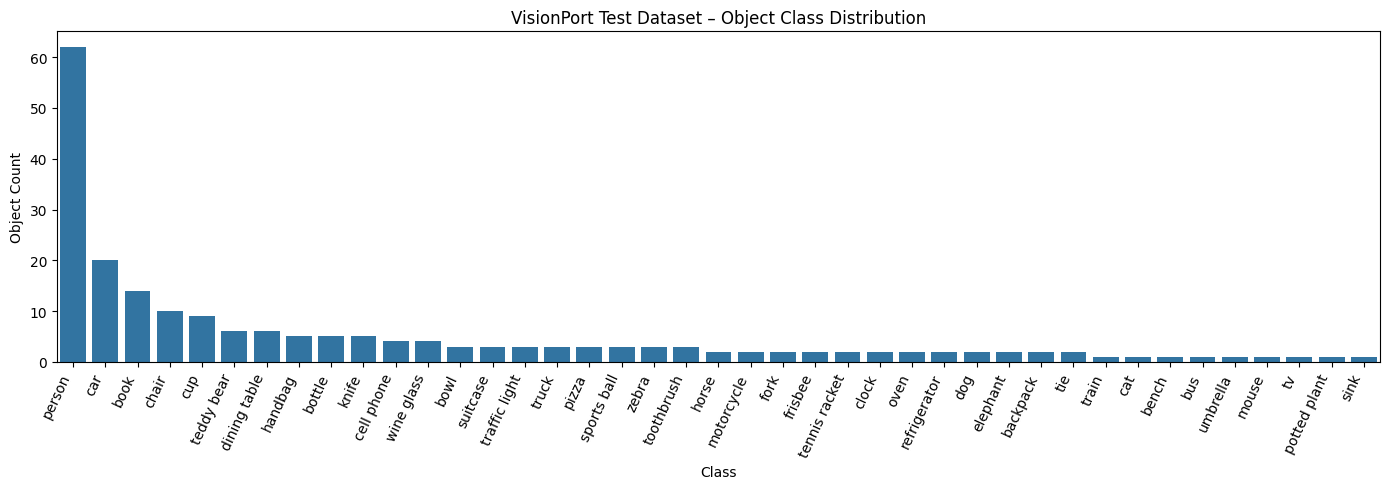

Valid annotations: 207
Missing labels: 1
Empty labels: 1
Invalid annotations: 1


In [ ]:
# 6. Class distribution and annotation validation
class_counts = Counter()
missing_labels, empty_labels, invalid_annotations = [], [], []
valid_annotations = 0

for rec in tqdm(records, desc="Validating annotations"):
    label_path = rec["label"]
    if not label_path.exists():
        missing_labels.append(str(rec["image"]))
        continue

    lines = label_path.read_text().splitlines()
    if not any(line.strip() for line in lines):
        empty_labels.append(str(label_path))
        continue

    for line_no, line in enumerate(lines, 1):
        if not line.strip():
            continue
        parts = line.split()
        if len(parts) != 5:
            invalid_annotations.append((str(label_path), line_no, "Expected 5 values"))
            continue
        try:
            cls, xc, yc, bw, bh = map(float, parts)
            vals = np.array([cls, xc, yc, bw, bh])
            if not np.isfinite(vals).all():
                raise ValueError("Non-finite value")
            if cls != int(cls) or not 0 <= int(cls) < NUM_CLASSES:
                raise ValueError("Invalid class ID")
            if not (0 <= xc <= 1 and 0 <= yc <= 1):
                raise ValueError("Bounding-box center outside normalized range")
            if not (0 < bw <= 1 and 0 < bh <= 1):
                raise ValueError("Invalid bounding-box width/height")
            if xc-bw/2 < -1e-6 or xc+bw/2 > 1+1e-6:
                raise ValueError("Bounding box exceeds horizontal boundary")
            if yc-bh/2 < -1e-6 or yc+bh/2 > 1+1e-6:
                raise ValueError("Bounding box exceeds vertical boundary")
            class_counts[int(cls)] += 1
            valid_annotations += 1
        except Exception as e:
            invalid_annotations.append((str(label_path), line_no, str(e)))

class_df = pd.DataFrame({
    "Class ID": range(NUM_CLASSES),
    "Class": [CLASS_NAMES[i] for i in range(NUM_CLASSES)],
    "Object Count": [class_counts[i] for i in range(NUM_CLASSES)]
})
display(class_df.sort_values("Object Count", ascending=False))

plot_df = class_df[class_df["Object Count"] > 0].sort_values("Object Count", ascending=False)
plt.figure(figsize=(14, 5))
sns.barplot(data=plot_df, x="Class", y="Object Count")
plt.title("VisionPort Test Dataset – Object Class Distribution")
plt.xticks(rotation=65, ha="right")
plt.tight_layout()
plt.show()

print("Valid annotations:", valid_annotations)
print("Missing labels:", len(missing_labels))
print("Empty labels:", len(empty_labels))
print("Invalid annotations:", len(invalid_annotations))


Checking image quality:   0%|          | 0/31 [00:00<?, ?it/s]

Readable images: 30
Corrupted/unreadable images: 1
Potentially blurry images (score < 100): 1


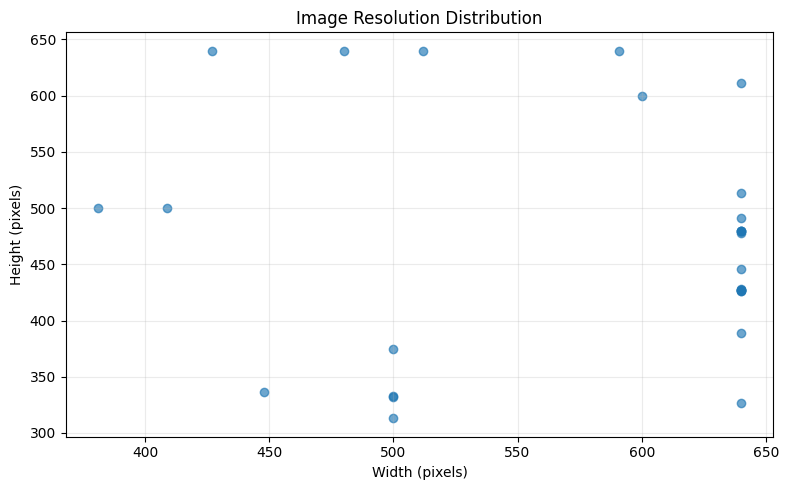

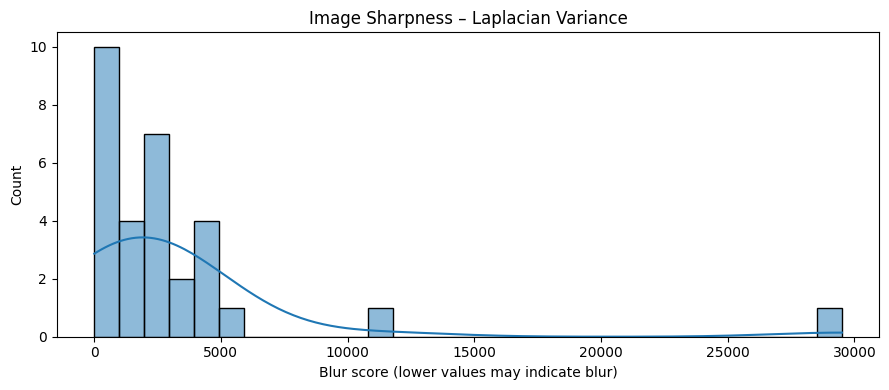

Blur detection is a heuristic; manually inspect flagged images.


In [ ]:
# 7. Image quality analysis
quality_rows, corrupted_images, blurry_images = [], [], []

for rec in tqdm(records, desc="Checking image quality"):
    path = rec["image"]
    image = cv2.imread(str(path))
    if image is None:
        corrupted_images.append(str(path))
        continue

    height, width = image.shape[:2]
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blur_score = float(cv2.Laplacian(gray, cv2.CV_64F).var())
    quality_rows.append({
        "Image": path.name, "Path": str(path),
        "Width": width, "Height": height, "Blur Score": blur_score
    })
    if blur_score < 100:
        blurry_images.append(str(path))

quality_df = pd.DataFrame(quality_rows)
print("Readable images:", len(quality_df))
print("Corrupted/unreadable images:", len(corrupted_images))
print("Potentially blurry images (score < 100):", len(blurry_images))

if not quality_df.empty:
    plt.figure(figsize=(8, 5))
    plt.scatter(quality_df["Width"], quality_df["Height"], alpha=0.65)
    plt.title("Image Resolution Distribution")
    plt.xlabel("Width (pixels)")
    plt.ylabel("Height (pixels)")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(9, 4))
    sns.histplot(quality_df["Blur Score"], bins=30, kde=True)
    plt.title("Image Sharpness – Laplacian Variance")
    plt.xlabel("Blur score (lower values may indicate blur)")
    plt.tight_layout()
    plt.show()

print("Blur detection is a heuristic; manually inspect flagged images.")


In [ ]:
# 8. Exact duplicate detection
hash_to_path, duplicate_pairs = {}, []

for rec in tqdm(records, desc="Finding exact duplicates"):
    path = rec["image"]
    try:
        digest = hashlib.md5(path.read_bytes()).hexdigest()
        if digest in hash_to_path:
            duplicate_pairs.append((hash_to_path[digest], str(path)))
        else:
            hash_to_path[digest] = str(path)
    except Exception as e:
        print("Could not hash", path, e)

print("Exact duplicate pairs:", len(duplicate_pairs))
print("This detects byte-identical files, not visually similar images.")


Finding exact duplicates:   0%|          | 0/31 [00:00<?, ?it/s]

Exact duplicate pairs: 1
This detects byte-identical files, not visually similar images.


In [ ]:
# 9. Visualise sample images with YOLO bounding boxes
def show_annotated_image(rec):
    image_bgr = cv2.imread(str(rec["image"]))
    if image_bgr is None:
        print("Skipping unreadable image:", rec["image"].name)
        return

    image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    h, w = image.shape[:2]

    if rec["label"].exists():
        for line in rec["label"].read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue
            try:
                cls, xc, yc, bw, bh = map(float, parts)
                if not np.isfinite([cls, xc, yc, bw, bh]).all():
                    continue
                x1, y1 = int((xc-bw/2)*w), int((yc-bh/2)*h)
                x2, y2 = int((xc+bw/2)*w), int((yc+bh/2)*h)
                cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
                name = CLASS_NAMES.get(int(cls), f"Class {int(cls)}")
                cv2.putText(image, name, (max(0, x1), max(18, y1-5)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 0, 0), 2)
            except Exception:
                continue

    plt.figure(figsize=(10, 7))
    plt.imshow(image)
    plt.title(rec["image"].name)
    plt.axis("off")
    plt.show()

shown = 0
for rec in random.sample(records, len(records)):
    if cv2.imread(str(rec["image"])) is not None:
        show_annotated_image(rec)
        shown += 1
    if shown == 5:
        break


In [ ]:
# 10. Final audit summary and CSV reports
audit = {
    "Total images discovered": len(records),
    "Readable images": len(quality_df),
    "Corrupted/unreadable images": len(corrupted_images),
    "Potentially blurry images": len(blurry_images),
    "Exact duplicate pairs": len(duplicate_pairs),
    "Missing label files": len(missing_labels),
    "Empty label files": len(empty_labels),
    "Valid annotations": valid_annotations,
    "Invalid annotations": len(invalid_annotations)
}
report_df = pd.DataFrame(list(audit.items()), columns=["Metric", "Value"])
display(report_df)

OUTPUT_DIR = Path("/content/VisionPort_Audit_Results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

class_df.to_csv(OUTPUT_DIR / "class_distribution.csv", index=False)
quality_df.to_csv(OUTPUT_DIR / "image_quality.csv", index=False)
report_df.to_csv(OUTPUT_DIR / "dataset_audit_summary.csv", index=False)
pd.DataFrame(invalid_annotations, columns=["Label File", "Line", "Error"]).to_csv(
    OUTPUT_DIR / "invalid_annotations.csv", index=False
)
pd.DataFrame({"Image": missing_labels}).to_csv(OUTPUT_DIR / "missing_labels.csv", index=False)
pd.DataFrame({"Label File": empty_labels}).to_csv(OUTPUT_DIR / "empty_labels.csv", index=False)
pd.DataFrame({"Image": corrupted_images}).to_csv(OUTPUT_DIR / "corrupted_images.csv", index=False)
pd.DataFrame({"Image": blurry_images}).to_csv(OUTPUT_DIR / "potentially_blurry_images.csv", index=False)
pd.DataFrame(duplicate_pairs, columns=["Original", "Duplicate"]).to_csv(
    OUTPUT_DIR / "duplicate_images.csv", index=False
)

print("Reports saved to:", OUTPUT_DIR)


,Metric,Value
0,Total images discovered,31
1,Readable images,30
2,Corrupted/unreadable images,1
3,Potentially blurry images,1
4,Exact duplicate pairs,1
5,Missing label files,1
6,Empty label files,1
7,Valid annotations,182
8,Invalid annotations,1


Reports saved to: /content/VisionPort_Audit_Results


In [ ]:
# 11. Package and download the audit reports
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/VisionPort_Audit_Results", "zip", OUTPUT_DIR
)
print("Created:", zip_path)
files.download(zip_path)
print("VISIONPORT DATASET AUDIT COMPLETED.")


Created: /content/VisionPort_Audit_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

VISIONPORT DATASET AUDIT COMPLETED.
